# **Architecture Transformer**



### Définition

Un **Transformer** est un réseau de neurones conçu pour traiter des séquences grâce au mécanisme d’**attention**.

Contrairement au RNN et au LSTM, il ne transmet pas une mémoire récurrente d’un instant au suivant. Il met directement en relation les positions d’une séquence et peut calculer leurs représentations en parallèle.

### Principaux composants

| Composant | Rôle |
|-----------|------|
| **Projection ou embedding** | Transformer chaque entrée en un vecteur |
| **Information de position** | Indiquer l’ordre des éléments dans la séquence |
| **Auto-attention multi-têtes** | Combiner les informations pertinentes provenant des différentes positions |
| **Réseau feed-forward** | Transformer la représentation de chaque position |
| **Connexions résiduelles et normalisation** | Faciliter et stabiliser l’apprentissage |
| **Couche de sortie** | Produire une prédiction adaptée à la tâche |

Un Transformer peut utiliser un **encodeur**, un **décodeur**, ou les deux. Notre exemple utilise uniquement un **encodeur**, suivi d’une couche linéaire.

### Fonctionnement du Self Attention

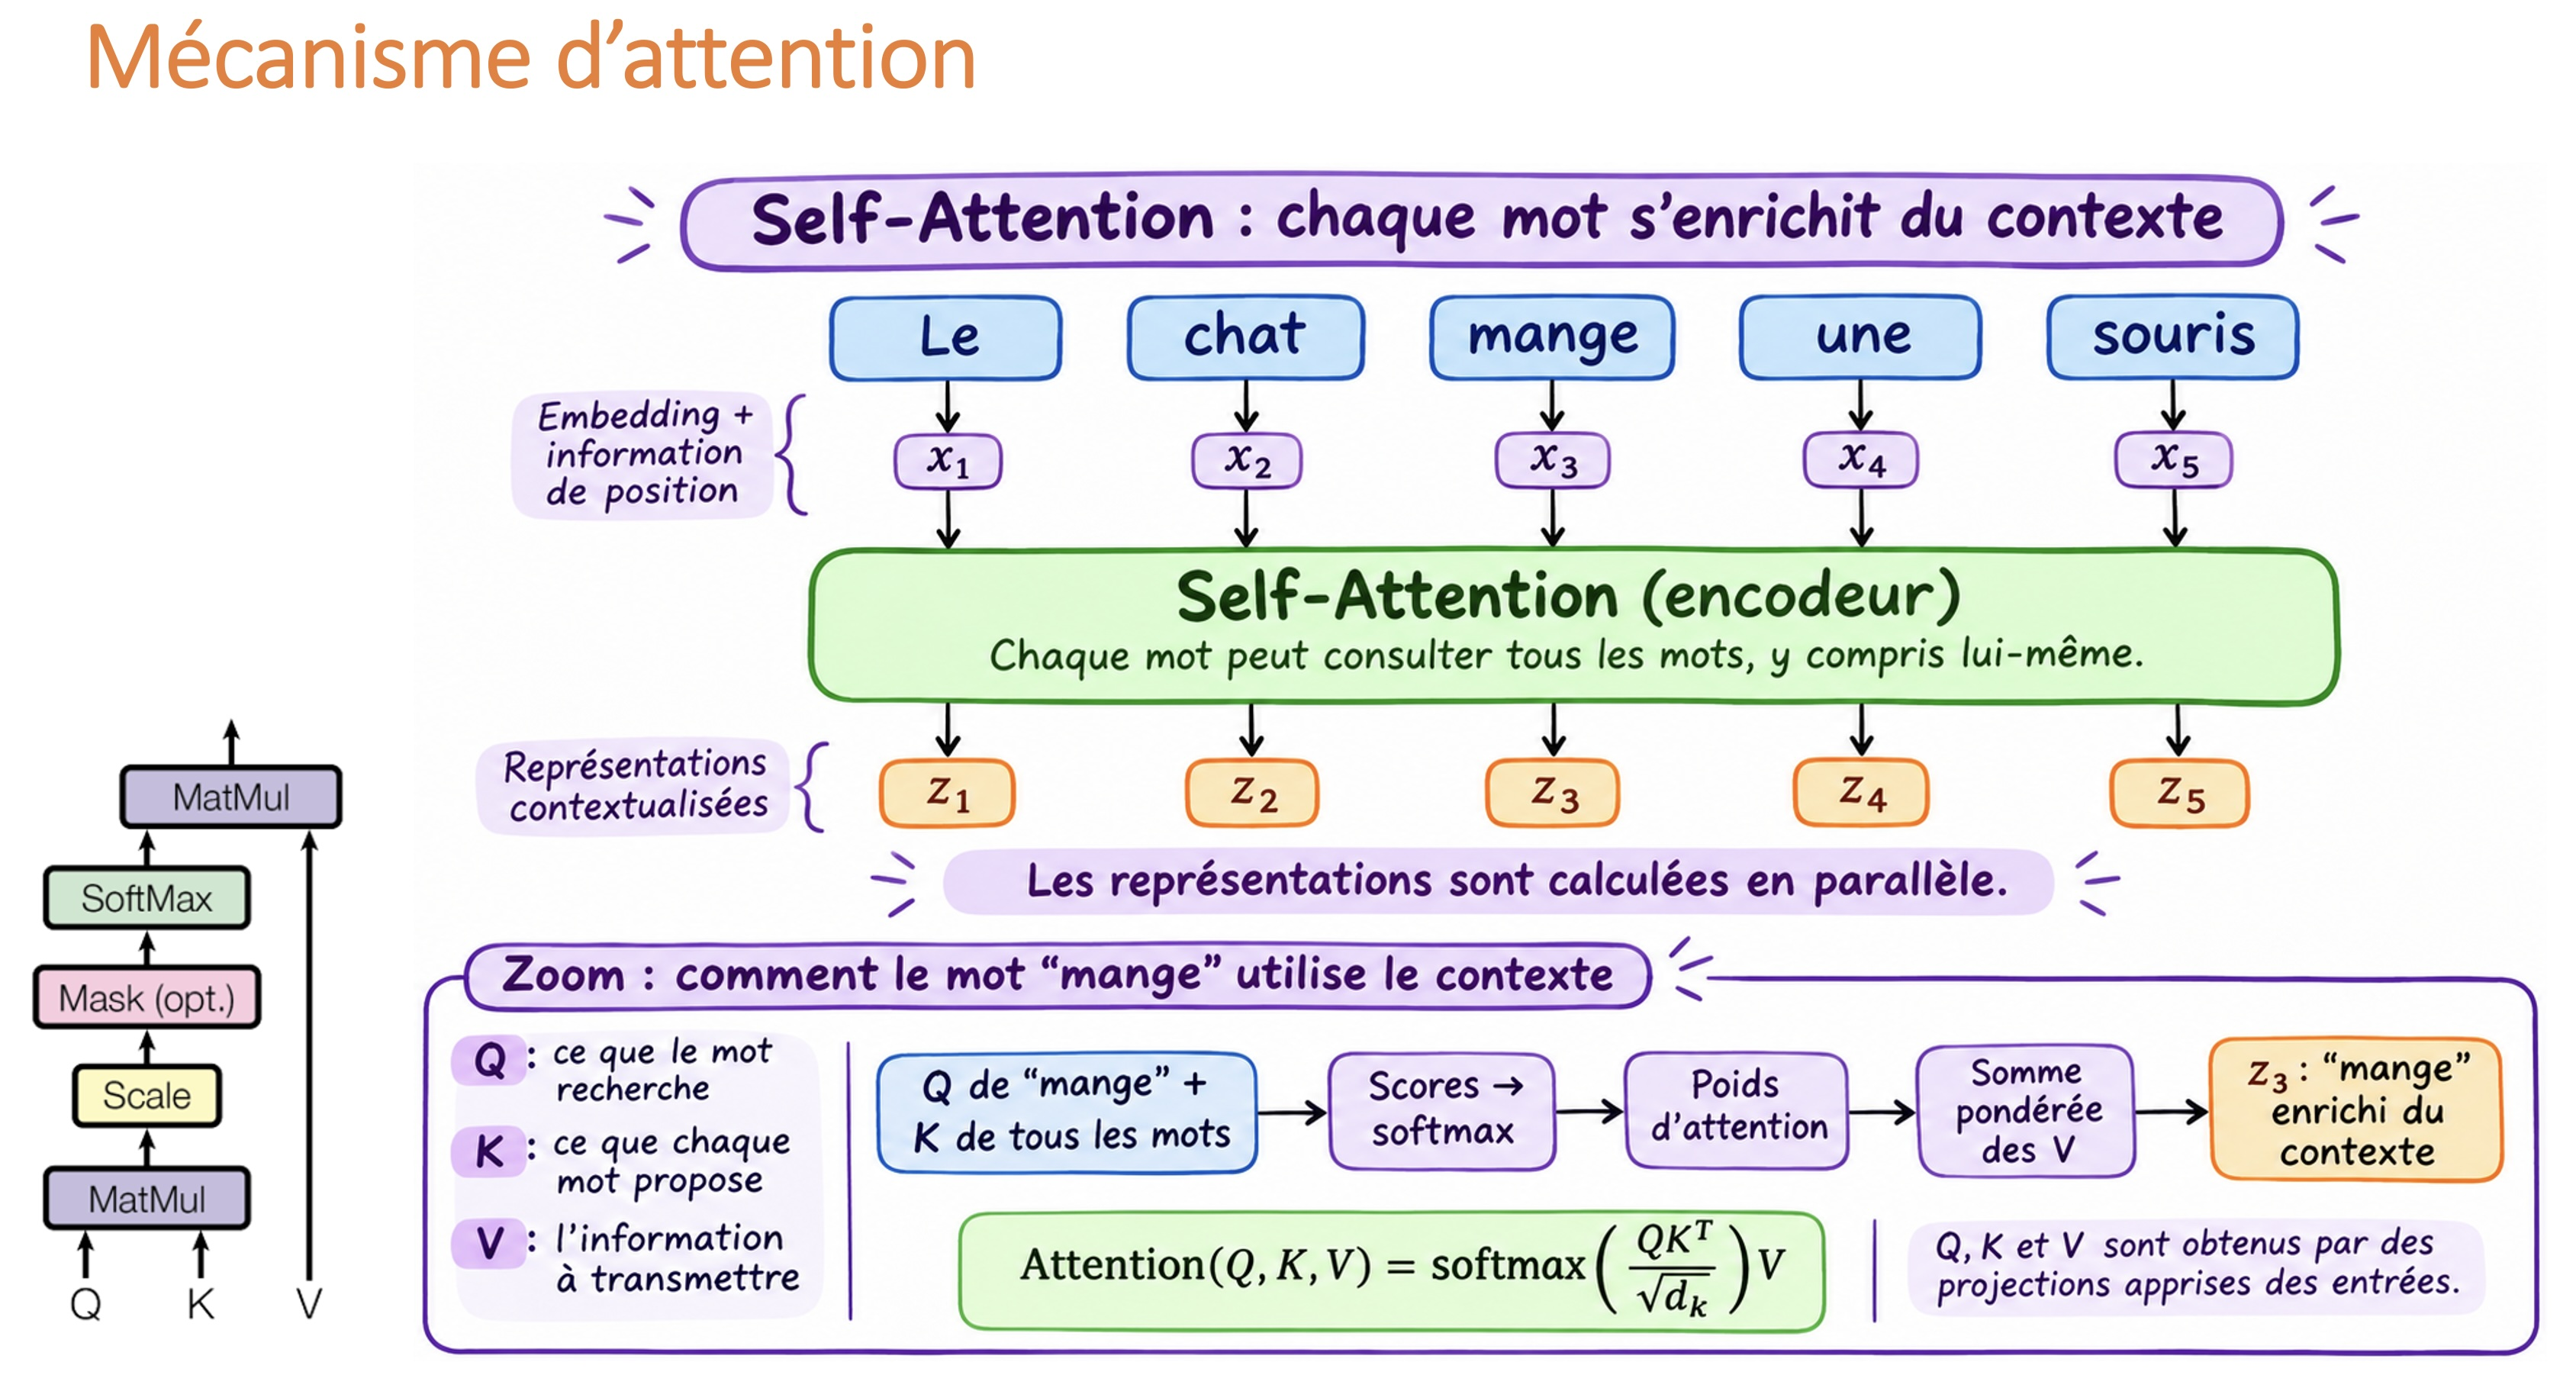


À partir des représentations d’entrée, le modèle calcule trois ensembles de vecteurs :

- **Q — Queries (requêtes)** : ce que chaque position recherche.
- **K — Keys (clés)** : ce que chaque position propose pour être comparée aux requêtes.
- **V — Values (valeurs)** : les informations à combiner.

L’attention est calculée par :

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

Le modèle compare les requêtes aux clés, obtient des poids d’attention, puis calcule une **combinaison pondérée des valeurs**.

L’attention **multi-têtes** effectue plusieurs calculs d’attention en parallèle pour apprendre différentes relations entre les positions.

### Architecture de notre exemple

Le modèle utilise **10 valeurs d’une sinusoïde pour prédire la suivante**.

| Élément | Configuration |
|---------|---------------|
| Entrée | 10 valeurs, avec une variable par instant |
| Projection | `nn.Linear(1, 16)` |
| Positions | Vecteurs appris avec `nn.Embedding(10, 16)` |
| Dimension des représentations | `d_model=16` |
| Têtes d’attention | `nhead=2`, soit 8 composantes par tête |
| Nombre de blocs d’encodeur | 1 |
| Réseau feed-forward | `16 → 32 → 16`, avec activation ReLU |
| Couche de sortie | `nn.Linear(16, 1)` |

    Séquence de 10 valeurs
              ↓
       Projection : 1 → 16
              ↓
    Ajout de l’information de position
              ↓
    Auto-attention à 2 têtes
              ↓
    Connexion résiduelle + normalisation
              ↓
    Réseau feed-forward : 16 → 32 → 16
              ↓
    Connexion résiduelle + normalisation
              ↓
    Représentation de la dernière position
              ↓
         Linear(16, 1)
              ↓
    Prédiction de la valeur suivante

Les dimensions sont :

$$
(B, 10, 1)
\xrightarrow{\text{projection + positions}}
(B, 10, 16)
\xrightarrow{\text{encodeur}}
(B, 10, 16)
\xrightarrow{\text{dernière position}}
(B, 16)
\xrightarrow{\text{Linear}}
(B, 1)
$$

$B$ représente le nombre de séquences traitées ensemble.

### Prédiction et apprentissage

1. **Projeter** les valeurs dans un espace de dimension 16.
2. **Ajouter les positions** pour représenter l’ordre.
3. **Combiner les informations** de la séquence avec l’auto-attention.
4. **Transformer les représentations** avec le réseau feed-forward.
5. **Prédire** à partir de la représentation de la dernière position.
6. **Mesurer l’erreur** avec la MSE, calculer les gradients par rétropropagation et ajuster les paramètres avec Adam.

Dans cet exemple, **aucun masque causal n’est nécessaire** : les 10 valeurs d’entrée sont toutes connues avant de prédire la onzième, qui n’est jamais fournie en entrée.

### Différence avec un RNN ou un LSTM

| RNN / LSTM | Transformer |
|------------|-------------|
| Traitement récurrent, pas à pas | Mise en relation directe des positions par attention |
| État transmis d’un instant au suivant | Pas de mémoire récurrente dans l’architecture standard |
| Ordre intégré au traitement séquentiel | Information de position à fournir explicitement |
| Calcul temporel difficile à paralléliser | Calcul des représentations parallélisable |

### Limite principale

L’auto-attention complète calcule les relations entre toutes les paires de positions. Son coût augmente donc **quadratiquement avec la longueur de la séquence**, ce qui peut devenir coûteux pour de longues entrées.

> **À retenir : un Transformer construit la représentation de chaque position en combinant les informations pertinentes de la séquence grâce à l’attention.**

In [48]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle Transformer
# --------------------------------------------------

class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        # Transformer chaque valeur en un vecteur de 16 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 10 positions.
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur Transformer.
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,       # Taille des représentations : 16
            nhead=2,                 # Deux têtes d'attention
            dim_feedforward=32,      # Taille interne du réseau feed-forward
            dropout=0.0,             # Désactivé pour simplifier l'exemple
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        # Transformer la représentation finale en une prédiction.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)

        # 1. Projection des valeurs
        x = self.projection(x)  # (B, 10, 16)

        # 2. Ajout de l'information de position
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)  # (10, 16)

        x = x + positions.unsqueeze(0)  # (B, 10, 16)

        # 3. Mise en relation des valeurs par auto-attention
        representations = self.encodeur(x)  # (B, 10, 16)

        # 4. Récupérer la représentation de la dernière position
        derniere_position = representations[:, -1, :]  # (B, 16)

        # 5. Prédire la valeur suivante
        return self.sortie(derniere_position)  # (B, 1)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


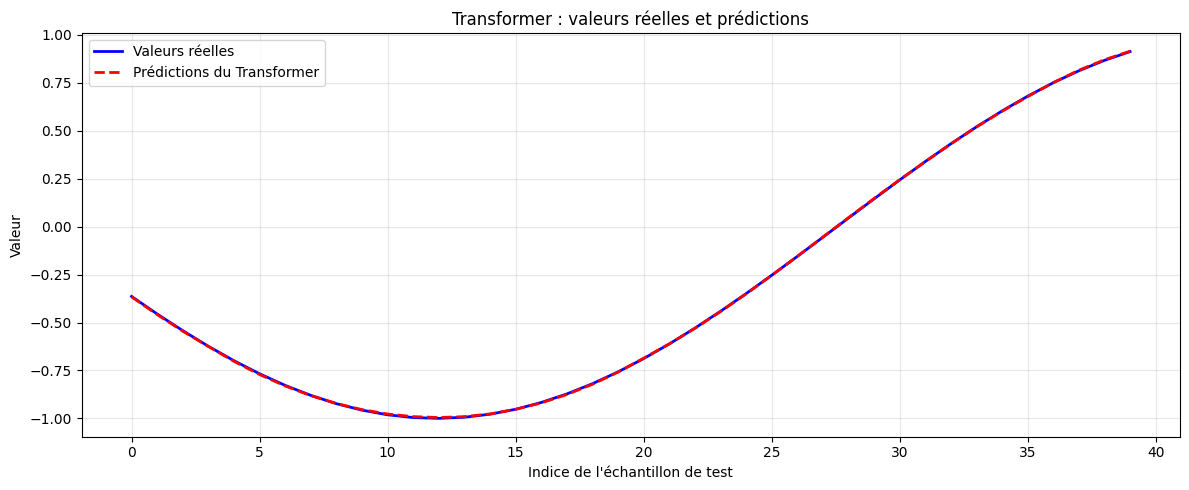

In [49]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Explication détaillée du code : prédiction avec un Transformer

## 1. Objectif du programme

Le programme entraîne un petit Transformer à **prédire la prochaine valeur d’une sinusoïde à partir de ses 10 valeurs précédentes**.

Le traitement comprend quatre étapes :

1. Préparer les données.
2. Construire le modèle.
3. Entraîner ses paramètres.
4. Évaluer ses prédictions sur les données de test.

Le modèle utilise un **encodeur Transformer suivi d’une couche linéaire**. Il ne contient pas de décodeur.

---

## 2. Importer les bibliothèques

- `import torch` importe PyTorch pour créer des tenseurs et effectuer les calculs.
- `import torch.nn as nn` importe les composants des réseaux de neurones : couches, fonctions de perte, etc.

`torch.manual_seed(42)` fixe la graine du générateur aléatoire. Cela aide à reproduire les résultats dans un même environnement, notamment l’initialisation des paramètres.

---

## 3. Créer la série temporelle

### Générer une sinusoïde

`serie = torch.sin(torch.linspace(0, 20, 200))`

Cette instruction effectue deux opérations :

1. `torch.linspace(0, 20, 200)` crée 200 valeurs régulièrement espacées entre 0 et 20.
2. `torch.sin(...)` calcule leur sinus.

Le résultat est un tenseur de forme **`(200,)`**, contenant 200 observations.

### Définir la longueur des entrées

`longueur_sequence = 10`

Chaque exemple utilisera 10 observations consécutives pour prédire la suivante.

---

## 4. Construire les entrées et les cibles

### Les entrées `X`

Pour chaque indice `i`, l’expression :

`serie[i:i + longueur_sequence]`

récupère 10 valeurs consécutives. La borne de fin est exclue.

`torch.stack(...)` rassemble toutes ces fenêtres dans un seul tenseur.

### Les cibles `y`

Pour chaque fenêtre, l’expression :

`serie[i + longueur_sequence]`

récupère la valeur immédiatement suivante.

| Exemple | Entrée | Cible |
|---------|--------|-------|
| 1 | $s_0, \ldots, s_9$ | $s_{10}$ |
| 2 | $s_1, \ldots, s_{10}$ | $s_{11}$ |
| 3 | $s_2, \ldots, s_{11}$ | $s_{12}$ |
| … | … | … |
| 190 | $s_{189}, \ldots, s_{198}$ | $s_{199}$ |

Le nombre d’exemples est :

$$
200 - 10 = 190
$$

À ce stade :

- `X` a la forme **`(190, 10)`**.
- `y` a la forme **`(190,)`**.

### Ajouter la dimension des variables

`X = X.unsqueeze(-1)` ajoute une dimension de taille 1 à la fin :

$$
(190, 10) \rightarrow (190, 10, 1)
$$

Cette dernière dimension indique qu’on observe une seule variable à chaque instant.

`y = y.unsqueeze(-1)` transforme les cibles :

$$
(190,) \rightarrow (190, 1)
$$

Cette forme correspondra à celle des prédictions : une valeur par exemple.

---

## 5. Séparer entraînement et test

Le découpage conserve l’ordre chronologique :

- `X[:150]` et `y[:150]` : les 150 premiers exemples pour l’entraînement.
- `X[150:]` et `y[150:]` : les 40 derniers pour le test.

| Tenseur | Dimensions |
|---------|------------|
| `X_train` | `(150, 10, 1)` |
| `y_train` | `(150, 1)` |
| `X_test` | `(40, 10, 1)` |
| `y_test` | `(40, 1)` |

Les fenêtres voisines partagent certaines observations : c’est normal avec une fenêtre glissante. Les cibles de test se situent après celles d’entraînement.

---

## 6. Définir la classe du modèle

`class PetitTransformer(nn.Module):`

Le modèle hérite de `nn.Module`, la classe de base des réseaux de neurones PyTorch.

Deux méthodes ont des rôles différents :

- `__init__` construit les couches et leurs paramètres.
- `forward` décrit les calculs appliqués aux entrées.

`super().__init__()` initialise la partie héritée de `nn.Module`, nécessaire notamment au suivi des paramètres.

Le paramètre `longueur_max=10` fixe le nombre maximal de positions disponibles dans ce modèle.

---

## 7. Projeter chaque valeur dans un vecteur

`dimension = 16`

Chaque position sera représentée par un vecteur de 16 nombres.

`self.projection = nn.Linear(1, dimension)`

Cette couche transforme chaque valeur scalaire en un vecteur :

$$
z_t = W_{\text{projection}}x_t + b_{\text{projection}}
$$

Les mêmes paramètres de projection sont appliqués à toutes les positions.

Pour un lot de `B` séquences :

$$
(B, 10, 1) \rightarrow (B, 10, 16)
$$

**Les 16 composantes ne correspondent pas à 16 instants.** Elles constituent la représentation d’une seule position.

---

## 8. Représenter les positions

`self.positions = nn.Embedding(longueur_max, dimension)`

Cette couche contient une table de **10 vecteurs appris de dimension 16** :

- un vecteur pour la position 0 ;
- un vecteur pour la position 1 ;
- …
- un vecteur pour la position 9.

L’auto-attention ne fournit pas, à elle seule, l’information d’ordre. Ces vecteurs permettent donc au modèle de distinguer les positions.

Ils sont ajustés pendant l’entraînement, comme les autres paramètres.

**Dans cette implémentation, les séquences ne peuvent pas dépasser `longueur_max` positions.**

---

## 9. Construire un bloc d’encodeur Transformer

`nn.TransformerEncoderLayer(...)` crée un bloc contenant principalement :

1. Une auto-attention multi-têtes.
2. Un réseau feed-forward.
3. Des connexions résiduelles et des normalisations.

### Signification des paramètres

| Paramètre | Explication |
|-----------|-------------|
| `d_model=16` | Chaque position est représentée par 16 nombres |
| `nhead=2` | Deux têtes d’attention sont calculées en parallèle |
| `dim_feedforward=32` | La couche interne du réseau feed-forward possède 32 unités |
| `dropout=0.0` | Le dropout est désactivé pour simplifier l’exemple |
| `batch_first=True` | Les tenseurs sont organisés sous la forme `(B, longueur, dimension)` |

### Auto-attention à deux têtes

Chaque tête utilise ici :

$$
16 / 2 = 8 \text{ composantes}
$$

Pour chaque position, l’attention apprend à pondérer les informations provenant des différentes positions de la séquence.

Les deux têtes peuvent apprendre des relations différentes. Leurs résultats sont concaténés puis projetés pour obtenir à nouveau 16 composantes par position.

**`d_model` doit être divisible par `nhead`.**

### Réseau feed-forward

Dans notre configuration, il suit cette architecture :

$$
16 \rightarrow 32 \rightarrow 16
$$

Il contient :

- une couche linéaire de 16 vers 32 ;
- une activation ReLU, utilisée par défaut ;
- une couche linéaire de 32 vers 16.

Ce même réseau est appliqué séparément à chaque position. Contrairement à l’attention, il ne mélange pas directement les positions entre elles.

### Connexions résiduelles et normalisation

Les connexions résiduelles ajoutent l’entrée d’un sous-bloc à sa sortie. Elles facilitent la circulation de l’information et des gradients.

La normalisation `LayerNorm` contribue à stabiliser les représentations.

Avec les réglages par défaut utilisés ici, le bloc suit l’ordre :

    Entrée
      ↓
    Auto-attention
      ↓
    Addition résiduelle + LayerNorm
      ↓
    Réseau feed-forward
      ↓
    Addition résiduelle + LayerNorm

Le bloc conserve la forme **`(B, 10, 16)`**.

---

## 10. Construire l’encodeur et la couche de sortie

### L’encodeur

`self.encodeur = nn.TransformerEncoder(couche, num_layers=1)`

Cette instruction construit un encodeur contenant un seul bloc.

`num_layers` permettrait d’en empiler plusieurs pour obtenir un modèle plus profond.

### La couche de sortie

`self.sortie = nn.Linear(dimension, 1)`

Cette couche transforme un vecteur de 16 nombres en une valeur prédite :

$$
\hat{y} = W_{\text{sortie}}z_{\text{final}} + b_{\text{sortie}}
$$

Aucune activation n’est ajoutée après cette couche.

---

## 11. Comprendre la méthode `forward`

### Étape 1 — Récupérer la longueur de la séquence

`longueur = x.size(1)`

Avec une entrée de forme `(B, 10, 1)`, la dimension d’indice 1 vaut 10.

### Étape 2 — Projeter les valeurs

`x = self.projection(x)`

Chaque valeur devient un vecteur de 16 composantes :

$$
(B, 10, 1) \rightarrow (B, 10, 16)
$$

### Étape 3 — Créer les indices de position

`indices = torch.arange(longueur, device=x.device)`

Cette instruction crée :

$$
[0, 1, 2, \ldots, 9]
$$

`device=x.device` place ces indices sur le même appareil que `x`, par exemple le CPU ou le GPU.

### Étape 4 — Récupérer les vecteurs de position

`positions = self.positions(indices)`

On obtient un tenseur de forme **`(10, 16)`**.

### Étape 5 — Ajouter les positions

`x = x + positions.unsqueeze(0)`

`unsqueeze(0)` transforme les positions en un tenseur de forme `(1, 10, 16)`.

Grâce à la diffusion automatique des dimensions, ou **broadcasting**, les mêmes vecteurs de position sont ajoutés à toutes les séquences du lot :

$$
(B, 10, 16) + (1, 10, 16) \rightarrow (B, 10, 16)
$$

### Étape 6 — Appliquer l’encodeur

`representations = self.encodeur(x)`

L’encodeur enrichit la représentation de chaque position à l’aide des autres positions.

La forme reste **`(B, 10, 16)`**.

### Étape 7 — Sélectionner la dernière position

`derniere_position = representations[:, -1, :]`

Cette sélection conserve :

- toutes les séquences avec le premier `:` ;
- la dernière position avec `-1` ;
- toutes les composantes avec le dernier `:`.

Le résultat a la forme **`(B, 16)`**.

Après l’attention, cette représentation peut intégrer des informations provenant des **10 valeurs**, et pas uniquement de la dernière.

### Étape 8 — Produire la prédiction

`return self.sortie(derniere_position)`

La couche linéaire produit une valeur par séquence :

$$
(B, 16) \rightarrow (B, 1)
$$

---

## 12. Pourquoi n’utilise-t-on pas de masque causal ?

Les 10 valeurs d’entrée sont toutes connues au moment de prédire la suivante.

Elles peuvent donc s’observer mutuellement dans l’attention sans accéder à la cible : **la onzième valeur n’est jamais fournie en entrée**.

Un masque causal serait nécessaire si l’on voulait prédire la valeur suivante à chaque position tout en interdisant l’accès aux positions ultérieures.

---

## 13. Préparer l’apprentissage

### Créer le modèle

`modele = PetitTransformer(longueur_max=longueur_sequence)`

Cette instruction construit le réseau et initialise ses paramètres.

### Définir la fonction de perte

`critere = nn.MSELoss()`

L’erreur quadratique moyenne mesure l’écart entre les prédictions et les cibles :

$$
L = \frac{1}{N}\sum_{i=1}^{N}(\hat{y}_i-y_i)^2
$$

### Définir l’optimiseur

`optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)`

Adam ajuste tous les paramètres entraînables, notamment :

- la projection d’entrée ;
- les vecteurs de position ;
- les paramètres de l’attention ;
- le réseau feed-forward et les normalisations ;
- la couche de sortie.

`lr=0.01` est le taux d’apprentissage.

---

## 14. Entraîner le modèle

`modele.train()` active le mode entraînement.

La boucle `for epoch in range(300):` effectue 300 époques.

À chaque époque :

| Instruction | Rôle |
|-------------|------|
| `predictions = modele(X_train)` | Calculer les prédictions |
| `perte = critere(predictions, y_train)` | Mesurer l’erreur |
| `optimiseur.zero_grad()` | Effacer les anciens gradients |
| `perte.backward()` | Calculer les nouveaux gradients par rétropropagation |
| `optimiseur.step()` | Mettre à jour les paramètres |

Les 150 séquences sont traitées ensemble : il y a donc **une mise à jour des paramètres par époque**.

Contrairement au RNN ou au LSTM, il n’y a pas ici de chaîne d’états récurrents à parcourir dans le temps lors de la rétropropagation.

### Afficher la progression

`if (epoch + 1) % 50 == 0:` affiche la perte toutes les 50 époques.

- `epoch + 1` numérote les époques à partir de 1.
- `% 50 == 0` repère les multiples de 50.
- `perte.item()` extrait le nombre contenu dans le tenseur.
- `:.6f` affiche six chiffres après la virgule.

La perte affichée a été calculée avant la mise à jour des paramètres de l’époque correspondante.

---

## 15. Tester le modèle

### Passer en mode évaluation

`modele.eval()` active le mode évaluation.

Comme le dropout est désactivé dans cet exemple, cela ne désactive aucune unité supplémentaire.

**Le mode évaluation ne désactive pas à lui seul le suivi des gradients.**

### Désactiver le suivi des gradients

`with torch.no_grad():` évite de construire le graphe nécessaire à leur calcul.

Cela réduit notamment la mémoire utilisée pendant l’évaluation.

### Calculer les prédictions et l’erreur

- `modele(X_test)` produit les 40 prédictions de test.
- `critere(predictions, y_test)` calcule leur MSE.

Aucune mise à jour des paramètres n’est effectuée.

### Afficher les résultats

Le programme affiche :

1. L’erreur moyenne sur les 40 exemples de test.
2. La cible du premier exemple : `y_test[0]`.
3. La prédiction correspondante : `predictions[0]`.

La comparaison affichée concerne donc **un seul exemple**, tandis que l’erreur de test résume **l’ensemble des exemples**.

---

## À retenir

Le cheminement des données est :

$$
\text{Valeurs}
\rightarrow
\text{Projection + positions}
\rightarrow
\text{Encodeur Transformer}
\rightarrow
\text{Dernière représentation}
\rightarrow
\text{Prédiction}
$$

**Le Transformer apprend à combiner les informations de la séquence grâce à l’attention, puis utilise cette représentation pour prédire la valeur suivante.**

# **GPT**

In [50]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié.
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

# --------------------------------------------------
# 2. Transformer le texte en tokens
# --------------------------------------------------

# GPT-2 est principalement entraîné sur de l'anglais.
texte = "Artificial intelligence can help people"

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# --------------------------------------------------
# 3. Générer la suite, un token après l'autre
# --------------------------------------------------

with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,       # Générer au maximum 50 tokens
        do_sample=True,          # Tirage aléatoire des tokens
        temperature=0.8,         # Contrôler la diversité
        top_p=0.9,               # Limiter les candidats probables
        pad_token_id=tokenizer.pad_token_id
    )

# --------------------------------------------------
# 4. Reconvertir les tokens en texte
# --------------------------------------------------

texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people and organizations create jobs and build organizations, which in turn will spur growth and prosperity.

However, when a company becomes more complex, it's likely that its users will be less interested in technology. The companies that make the software that makes things


# Générer du texte avec GPT-2

## 1. Objectif

Cette implémentation utilise **GPT-2 préentraîné** pour générer la suite d’un texte.

Exemple d’entrée :

> Artificial intelligence can help people

Le modèle prédit un token suivant, l’ajoute au texte, puis recommence. Ce fonctionnement est appelé **génération autorégressive**.

Contrairement à BERT, GPT-2 ne complète pas un masque en regardant les deux côtés : il prédit la suite à partir des tokens déjà disponibles.

## 2. Charger le tokenizer et le modèle

Nous utilisons le modèle `gpt2`, principalement entraîné sur des textes en anglais.

- **`AutoTokenizer`** transforme le texte en tokens, puis en identifiants numériques.
- **`AutoModelForCausalLM`** charge GPT-2 avec une tête de prédiction du prochain token.
- **`modele.eval()`** place le modèle en mode évaluation, notamment en désactivant le dropout.

Le modèle est déjà entraîné : aucun entraînement supplémentaire n’est effectué dans cet exemple.

Le premier lancement télécharge les fichiers du modèle et du tokenizer.

## 3. Configurer le token de remplissage

GPT-2 ne possède pas de token de remplissage dédié par défaut.

L’instruction :

`tokenizer.pad_token = tokenizer.eos_token`

utilise le token de fin de texte comme token de remplissage.

L’instruction :

`modele.config.pad_token_id = tokenizer.pad_token_id`

renseigne cette configuration dans le modèle.

Le remplissage sert notamment à regrouper des séquences de longueurs différentes dans un même batch. Avec une seule phrase, comme ici, il n’est généralement pas nécessaire d’ajouter du remplissage.

## 4. Transformer le texte en tenseurs

L’appel :

`tokenizer(texte, return_tensors="pt")`

convertit le texte en tenseurs PyTorch. Il produit notamment :

| Élément | Rôle |
|---|---|
| `input_ids` | Identifiants numériques des tokens |
| `attention_mask` | Distingue les tokens utiles des éventuels tokens de remplissage |

La forme de `input_ids` est **`(1, L)`**, où :

- **1** représente le nombre de textes dans le batch ;
- **L** représente le nombre de tokens du texte initial.

> Un token n’est pas forcément un mot entier : il peut représenter un mot, une partie de mot ou un signe de ponctuation.

## 5. Comprendre le fonctionnement de GPT-2

GPT-2 est un Transformer **de type décodeur uniquement**.

Les identifiants des tokens sont transformés en vecteurs, auxquels sont ajoutées des représentations de position. Ces vecteurs traversent ensuite plusieurs blocs Transformer.

Chaque bloc contient notamment :

- une **auto-attention causale multi-têtes** ;
- un réseau **feed-forward** ;
- des connexions résiduelles ;
- des normalisations.

L’attention causale empêche une position de regarder les tokens futurs. Elle peut seulement utiliser les tokens précédents et le token courant.

À la sortie, le modèle calcule des scores sur son vocabulaire pour prédire le token suivant.

## 6. Générer la suite du texte

L’appel :

`modele.generate(**entrees, ...)`

gère automatiquement la génération token par token.

À chaque étape :

1. le modèle utilise le texte déjà disponible ;
2. il calcule les scores des tokens possibles ;
3. un token est sélectionné selon les paramètres de génération ;
4. ce token est ajouté à la séquence ;
5. le processus recommence jusqu’à une condition d’arrêt.

Le calcul est effectué dans `torch.no_grad()` pour désactiver le suivi des gradients et réduire la mémoire utilisée pendant l’inférence.

## 7. Comprendre les paramètres de génération

| Paramètre | Valeur | Rôle |
|---|---|---|
| `max_new_tokens` | `50` | Génère au maximum 50 nouveaux tokens, sans compter le texte initial |
| `do_sample` | `True` | Active une sélection aléatoire des tokens selon leurs probabilités |
| `temperature` | `0.8` | Rend la distribution plus concentrée qu’avec une température de 1 |
| `top_p` | `0.9` | Limite le tirage aux tokens les plus probables dont la probabilité cumulée atteint au moins 90 % |
| `pad_token_id` | Identifiant du token de fin | Indique le token utilisé pour le remplissage si nécessaire |

### Température

La température ajuste les scores avant leur conversion en probabilités :

- **inférieure à 1** : favorise davantage les tokens les plus probables ;
- **égale à 1** : conserve la distribution non ajustée ;
- **supérieure à 1** : rend la distribution plus diffuse.

### Échantillonnage `top_p`

Le paramètre `top_p` adapte le nombre de candidats à chaque étape :

- si quelques tokens concentrent presque toute la probabilité, peu de candidats sont conservés ;
- si les probabilités sont plus dispersées, davantage de candidats sont conservés.

Avec `do_sample=True`, plusieurs exécutions peuvent produire des textes différents.

La génération peut s’arrêter avant 50 nouveaux tokens si le modèle produit son token de fin.

## 8. Reconvertir les tokens en texte

L’expression :

`tokenizer.decode(sortie[0], skip_special_tokens=True)`

convertit la première séquence générée en texte lisible.

- **`sortie[0]`** sélectionne la première séquence du batch.
- **`skip_special_tokens=True`** retire les tokens spéciaux de l’affichage.

Pour GPT-2, la séquence renvoyée par `generate()` contient **le texte initial suivi du texte généré**.

## 9. Résumé du fonctionnement

Texte initial  
↓  
Tokenisation  
↓  
Embeddings des tokens + positions  
↓  
Blocs Transformer avec attention causale  
↓  
Scores sur le vocabulaire  
↓  
Sélection du prochain token  
↓  
Ajout du token à la séquence  
↓  
Répétition jusqu’à l’arrêt  
↓  
Décodage en texte lisible

**À retenir :** GPT-2 génère du texte un token à la fois à partir du contexte précédent. Il produit une continuation plausible, mais ne garantit ni son exactitude ni sa cohérence.

# **BERT**

In [51]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

modele.eval()

# --------------------------------------------------
# 2. Préparer un texte avec un token masqué
# --------------------------------------------------

texte = f"Paris est la {tokenizer.mask_token} de la France."

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# --------------------------------------------------
# 3. Prédire le token masqué
# --------------------------------------------------

with torch.no_grad():
    sortie = modele(**entrees)

# sortie.logits : (1, nombre de tokens, taille du vocabulaire)
scores = sortie.logits[0, position_masque, :]

# Transformer les scores en probabilités
probabilites = torch.softmax(scores, dim=-1)

# Sélectionner les 5 tokens les plus probables
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# --------------------------------------------------
# 4. Afficher les propositions
# --------------------------------------------------

print("\nPropositions de BERT :")

for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()

    phrase = texte.replace(tokenizer.mask_token, token)

    print(f"{probabilite.item():.2%} | {phrase}")

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Some weights of the model checkpoint at bert-base-multilingual-cased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Texte : Paris est la [MASK] de la France.
Dimensions de l'entrée : torch.Size([1, 10])

Propositions de BERT :
36.33% | Paris est la capitale de la France.
21.09% | Paris est la ville de la France.
3.16% | Paris est la Cité de la France.
1.67% | Paris est la préfecture de la France.
1.64% | Paris est la banlieue de la France.


# Compléter un texte avec BERT

## 1. Objectif

Cette implémentation utilise **BERT préentraîné** pour retrouver un token masqué dans une phrase.

Exemple d’entrée :

> Paris est la [MASK] de la France.

Le modèle attribue une probabilité à chaque token de son vocabulaire pour remplacer `[MASK]`. Une réponse attendue serait **« capitale »**, mais les propositions dépendent du modèle.

Contrairement à GPT, BERT ne cherche pas ici à générer la suite du texte : il utilise le contexte **avant et après le masque** pour compléter la phrase.

## 2. Charger le tokenizer et le modèle

Nous utilisons `bert-base-multilingual-cased`, une version multilingue de BERT qui prend en charge le français et distingue les majuscules des minuscules.

- **`AutoTokenizer`** transforme le texte en tokens, puis en identifiants numériques.
- **`AutoModelForMaskedLM`** charge BERT avec une tête de prédiction adaptée aux tokens masqués.
- **`modele.eval()`** place le modèle en mode évaluation, notamment en désactivant le dropout.

Le modèle est déjà entraîné : aucun entraînement supplémentaire n’est effectué dans cet exemple.

## 3. Préparer la phrase

`tokenizer.mask_token` fournit le token de masque attendu par le modèle, ici `[MASK]`.

L’appel `tokenizer(texte, return_tensors="pt")` transforme la phrase en tenseurs PyTorch. Il produit notamment :

| Élément | Rôle |
|---|---|
| `input_ids` | Identifiants numériques des tokens |
| `attention_mask` | Distingue les tokens utiles des éventuels tokens de remplissage |
| `token_type_ids` | Indique le segment auquel appartient chaque token ; ici, un seul segment |

Le tokenizer ajoute également les tokens spéciaux nécessaires à BERT, notamment `[CLS]` et `[SEP]`.

La forme de `input_ids` est **`(1, L)`**, où `L` est le nombre de tokens, tokens spéciaux inclus.

> Un token n’est pas forcément un mot entier : certains mots sont découpés en plusieurs sous-mots.

## 4. Repérer la position du masque

La comparaison :

`entrees["input_ids"][0] == tokenizer.mask_token_id`

permet de repérer le token `[MASK]` dans la séquence.

`nonzero()` récupère sa position et `item()` la convertit en entier Python.

Cette implémentation suppose que la phrase contient **exactement un masque**.

## 5. Calculer les prédictions

L’appel `modele(**entrees)` transmet les tenseurs d’entrée au modèle.

BERT construit une représentation de chaque position grâce à son **attention bidirectionnelle** : le masque peut utiliser aussi bien « Paris est la » que « de la France ».

Le calcul est effectué dans `torch.no_grad()` pour désactiver le suivi des gradients et réduire la mémoire utilisée pendant l’inférence.

La sortie `sortie.logits` a la forme :

**`(1, L, V)`**

avec :

- **1** : le nombre de phrases dans le batch ;
- **L** : le nombre de tokens de la séquence ;
- **V** : la taille du vocabulaire.

Les logits sont des scores bruts, pas encore des probabilités.

## 6. Sélectionner les scores du masque

L’expression :

`sortie.logits[0, position_masque, :]`

sélectionne les scores de tous les tokens du vocabulaire pour la position masquée de la première phrase.

Le tenseur obtenu a la forme **`(V,)`**.

## 7. Obtenir les cinq meilleures propositions

`torch.softmax(scores, dim=-1)` transforme les scores en probabilités dont la somme vaut 1 sur l’ensemble du vocabulaire.

`torch.topk(probabilites, k=5)` sélectionne ensuite :

- les cinq probabilités les plus élevées ;
- les identifiants des tokens correspondants.

Ces probabilités reflètent les préférences du modèle dans ce contexte : elles ne garantissent pas qu’une proposition est correcte.

## 8. Afficher les phrases complétées

Pour chaque proposition :

1. `tokenizer.decode()` transforme l’identifiant du token en texte ;
2. `replace()` remplace `[MASK]` par ce texte ;
3. le programme affiche la phrase complétée et sa probabilité.

Cette reconstruction est simple et adaptée à l’exemple. Certains candidats peuvent toutefois être des sous-mots plutôt que des mots complets.

## 9. Résumé du fonctionnement

Phrase avec un masque  
↓  
Tokenisation  
↓  
BERT : analyse du contexte à gauche et à droite  
↓  
Scores du vocabulaire à la position masquée  
↓  
Softmax  
↓  
Sélection des cinq tokens les plus probables  
↓  
Affichage des propositions

**À retenir :** GPT prédit généralement le prochain token à partir du contexte précédent, tandis que BERT peut prédire un token masqué en utilisant les deux côtés de la phrase.